In [11]:
import pandas as pd

pd.set_option('display.max_rows', 50)
pd.set_option('display.max_columns', 50)
pd.set_option('display.max_colwidth', None)

dictionary = pd.read_csv('data_dictionary.csv')
train = pd.read_csv('train.csv')
test = pd.read_csv('test.csv')

print(f"Train shape: {train.shape[0]} rows, {train.shape[1]} columns")
print(f"Test shape: {test.shape[0]} rows, {test.shape[1]} columns\n")

print("=== MISSING VALUES IN TRAIN (%) ===")
missing_train = (train.isnull().sum() / len(train)) * 100
print(missing_train[missing_train > 0].sort_values(ascending=False))

print("\n=== MISSING VALUES IN TEST (%) ===")
missing_test = (test.isnull().sum() / len(test)) * 100
print(missing_test[missing_test > 0].sort_values(ascending=False))

print("\n=== SUMMARY STATS ===")
display(train.describe().T[['count', 'mean', 'min', '50%', 'max']])

Train shape: 16972 rows, 45 columns
Test shape: 2810 rows, 44 columns

=== MISSING VALUES IN TRAIN (%) ===
soil_ph                    17.794014
soil_nitrogen_pct          17.794014
soil_organic_carbon_pct    17.794014
soil_p_ppm                 17.794014
ndvi_peak                  13.386755
manure_t_ha                 5.538534
education_years             5.061277
seed_rate_kg_ha             5.061277
hh_head_age                 3.788593
fertilizer_urea_kg_ha       2.863540
longest_dry_spell_days      2.056328
dtype: float64

=== MISSING VALUES IN TEST (%) ===
soil_ph                    18.469751
soil_nitrogen_pct          18.469751
soil_organic_carbon_pct    18.469751
soil_p_ppm                 18.469751
ndvi_peak                  13.843416
manure_t_ha                 6.085409
seed_rate_kg_ha             5.266904
education_years             4.448399
hh_head_age                 3.950178
fertilizer_urea_kg_ha       3.060498
longest_dry_spell_days      2.135231
dtype: float64

=== SUMMARY 

,count,mean,min,50%,max
latitude,16972.0,0.155536,-9.2238,-0.0061,10.6724
longitude,16972.0,34.629690,29.3207,34.9989,38.8074
altitude_m,16972.0,1557.585729,712.0000,1529.0000,2510.0000
year,16972.0,2020.503182,2018.0000,2020.0000,2023.0000
farm_size_ha,16972.0,1.307093,0.1000,1.0600,8.8700
plot_size_ha,16972.0,0.595841,0.0400,0.4580,7.0820
hh_head_age,16329.0,45.544246,19.0000,46.0000,85.0000
hh_size,16972.0,5.463528,1.0000,5.0000,15.0000
education_years,16113.0,6.126668,0.0000,6.0000,16.0000
coop_member,16972.0,0.343978,0.0000,0.0000,1.0000


In [12]:
cat_cols = train.select_dtypes(include=['object', 'string']).columns
print("Categorical columns:", list(cat_cols), "\n")

for col in cat_cols:
    print(f"--- {col} (Missing: {train[col].isnull().sum()}) ---")
    print(train[col].value_counts(dropna=False).head(10))
    print()

print("=== CORRELATION WITH YIELD ===")
correlations = train.corr(numeric_only=True)['yield_kg_ha'].sort_values(ascending=False)
print(correlations)


Categorical columns: ['record_id', 'farm_id', 'country', 'region', 'agro_ecological_zone', 'season', 'hh_head_gender', 'soil_type', 'seed_type', 'intercrop', 'faw_incidence'] 

--- record_id (Missing: 0) ---
record_id
R010333    2
R013259    2
R008193    2
R013501    2
R014983    2
R000665    2
R010136    2
R002299    2
R009055    2
R000615    2
Name: count, dtype: int64

--- farm_id (Missing: 0) ---
farm_id
F01140    13
F00354    13
F01128    13
F00156    13
F00395    12
F00614    12
F00862    12
F00695    12
F00167    12
F00430    12
Name: count, dtype: int64

--- country (Missing: 0) ---
country
Kenya       5261
Uganda      3843
Rwanda      2840
Tanzania    2744
Ethiopia    2284
Name: count, dtype: int64

--- region (Missing: 0) ---
region
Musanze      1137
Iganga       1116
Bungoma      1088
Nakuru       1079
Masindi      1071
Kayonza      1011
Arusha        986
Sidama        891
Kapchorwa     880
Meru          795
Name: count, dtype: int64

--- agro_ecological_zone (Missing: 0) --

In [13]:
# 1. Inspect duplicate record_ids in train
dups = train[train.duplicated(subset=['record_id'], keep=False)].sort_values('record_id')
print(f"Total rows with duplicate record_ids in train: {len(dups)}")
display(dups.head(6))

# 2. Check if test has duplicate record_ids
print("Duplicate record_ids in test:", test['record_id'].duplicated().sum())

# 3. Check unique values of seed_type and intercrop in test
print("\nTest seed_type:", test['seed_type'].value_counts(dropna=False).to_dict())
print("Test intercrop:", test['intercrop'].value_counts(dropna=False).to_dict())

Total rows with duplicate record_ids in train: 50


,record_id,farm_id,country,region,agro_ecological_zone,latitude,longitude,altitude_m,year,season,farm_size_ha,plot_size_ha,hh_head_gender,hh_head_age,hh_size,education_years,coop_member,extension_visits,access_to_credit,distance_to_market_km,soil_type,soil_ph,soil_organic_carbon_pct,soil_nitrogen_pct,soil_p_ppm,slope_pct,seed_type,seed_rate_kg_ha,planting_delay_days,fertilizer_dap_kg_ha,fertilizer_urea_kg_ha,manure_t_ha,intercrop,weeding_count,pesticide_used,irrigation,seasonal_rainfall_mm,rainfall_onset_doy,longest_dry_spell_days,mean_tmax_c,ndvi_peak,faw_incidence,mln_reported,striga_present,yield_kg_ha
8341,R000028,F00354,Kenya,Nakuru,Highland sub-humid,-0.3739,36.1438,1966,2022,Short rains,3.24,1.868,Female,37.0,5,4.0,0,1,0,11.2,Vertisol,5.62,0.97,0.072,6.5,5.3,Local/recycled,24.7,16,16.6,0.0,NaN,Cowpea,2,0,0,308.7,296,6.0,20.3,NaN,Medium,1,0,614.0
11016,R000028,F00354,Kenya,Nakuru,Highland sub-humid,-0.3739,36.1438,1966,2022,Short rains,3.24,1.868,Female,37.0,5,4.0,0,1,0,11.2,Vertisol,5.62,0.97,0.072,6.5,5.3,Local/recycled,24.7,16,16.6,0.0,NaN,Cowpea,2,0,0,308.7,296,6.0,20.3,NaN,Medium,1,0,614.0
8747,R000059,F01105,Tanzania,Arusha,Mid-altitude semi-arid,-3.2793,36.6955,1469,2019,Masika,1.60,0.524,Female,45.0,3,4.0,0,2,0,8.1,Nitisol,NaN,NaN,NaN,NaN,4.9,Hybrid,29.1,12,77.9,NaN,0.0,Sole maize,2,1,0,409.8,75,7.0,22.5,0.593,High,0,0,1906.0
7415,R000059,F01105,Tanzania,Arusha,Mid-altitude semi-arid,-3.2793,36.6955,1469,2019,Masika,1.60,0.524,Female,45.0,3,4.0,0,2,0,8.1,Nitisol,NaN,NaN,NaN,NaN,4.9,Hybrid,29.1,12,77.9,NaN,0.0,Sole maize,2,1,0,409.8,75,7.0,22.5,0.593,High,0,0,1906.0
14742,R000615,F00409,Kenya,Machakos,Mid-altitude semi-arid,-1.5629,37.3055,1356,2021,Long rains,0.28,0.140,Male,31.0,4,4.0,0,0,0,2.2,Nitisol,6.01,1.96,0.146,11.6,1.8,Hybrid,26.3,9,91.5,72.9,0.0,Sole maize,1,1,0,475.3,70,2.0,24.0,0.552,Low,0,0,1920.0
3367,R000615,F00409,Kenya,Machakos,Mid-altitude semi-arid,-1.5629,37.3055,1356,2021,Long rains,0.28,0.140,Male,31.0,4,4.0,0,0,0,2.2,Nitisol,6.01,1.96,0.146,11.6,1.8,Hybrid,26.3,9,91.5,72.9,0.0,Sole maize,1,1,0,475.3,70,2.0,24.0,0.552,Low,0,0,1920.0


Duplicate record_ids in test: 0

Test seed_type: {'Hybrid': 1649, 'Local/recycled': 685, 'OPV': 430, 'HYBRID': 33, 'LOCAL/RECYCLED': 13}
Test intercrop: {'Sole maize': 1341, 'Beans': 976, 'Cowpea': 245, 'Pigeonpea': 158, 'beans': 46, 'Desmodium (push-pull)': 44}


In [14]:
def clean_data(train_df, test_df):
    train = train_df.copy()
    test = test_df.copy()
    
    # 1. Drop exact duplicate records in train only
    train = train.drop_duplicates(subset=['record_id']).reset_index(drop=True)
    
    # 2. Fix text capitalization inconsistencies in both train and test
    for df in [train, test]:
        df['seed_type'] = df['seed_type'].str.strip().str.capitalize()
        # Restore 'Opv' back to uppercase 'OPV' for readability
        df['seed_type'] = df['seed_type'].replace({'Opv': 'OPV'})
        
        df['intercrop'] = df['intercrop'].str.strip().str.capitalize()
        # Restore 'Desmodium (push-pull)' capitalization
        df['intercrop'] = df['intercrop'].replace({'Desmodium (push-pull)': 'Desmodium (push-pull)'})

    # 3. Domain-smart Soil Imputation (by farm_id first, then by soil_type median)
    soil_cols = ['soil_ph', 'soil_organic_carbon_pct', 'soil_nitrogen_pct', 'soil_p_ppm']
    
    # Combine features temporarily ONLY to look up static farm_id soil tests across years
    all_farms = pd.concat([train[['farm_id', 'soil_type'] + soil_cols], 
                           test[['farm_id', 'soil_type'] + soil_cols]])
    
    farm_soil_map = all_farms.groupby('farm_id')[soil_cols].median()
    soil_type_map = train.groupby('soil_type')[soil_cols].median()
    
    for col in soil_cols:
        # Fill using same farm_id's soil test from another season
        train[col] = train[col].fillna(train['farm_id'].map(farm_soil_map[col]))
        test[col] = test[col].fillna(test['farm_id'].map(farm_soil_map[col]))
        
        # If farm never had a soil test, fill using the median for its soil_type (learned from train)
        train[col] = train[col].fillna(train['soil_type'].map(soil_type_map[col]))
        test[col] = test[col].fillna(test['soil_type'].map(soil_type_map[col]))

    # 4. Fill remaining numeric gaps using medians learned strictly from train
    num_missing_cols = ['ndvi_peak', 'manure_t_ha', 'education_years', 
                        'seed_rate_kg_ha', 'hh_head_age', 'fertilizer_urea_kg_ha', 
                        'longest_dry_spell_days']
    
    for col in num_missing_cols:
        median_val = train[col].median()
        train[col] = train[col].fillna(median_val)
        test[col] = test[col].fillna(median_val)
        
    return train, test

train_clean, test_clean = clean_data(train, test)

print("New Train shape:", train_clean.shape)
print("New Test shape:", test_clean.shape)
print("Remaining missing in Train:", train_clean.isnull().sum().sum())
print("Remaining missing in Test:", test_clean.isnull().sum().sum())
print("\nClean seed_type values:", train_clean['seed_type'].unique())
print("Clean intercrop values:", train_clean['intercrop'].unique())

New Train shape: (16947, 45)
New Test shape: (2810, 44)
Remaining missing in Train: 0
Remaining missing in Test: 0

Clean seed_type values: <StringArray>
['Hybrid', 'Local/recycled', 'OPV']
Length: 3, dtype: str
Clean intercrop values: <StringArray>
['Sole maize', 'Beans', 'Cowpea', 'Desmodium (push-pull)', 'Pigeonpea']
Length: 5, dtype: str


In [23]:
import numpy as np
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import root_mean_squared_error, r2_score

def engineer_features(df, raw_df):
    d = df.copy()
    
    # 1. Domain features
    d['total_fertilizer_kg_ha'] = d['fertilizer_dap_kg_ha'] + d['fertilizer_urea_kg_ha']
    d['drought_stress'] = d['longest_dry_spell_days'] / (d['seasonal_rainfall_mm'] + 1)
    d['disease_count'] = d['mln_reported'] + d['striga_present']
    
    # Flag whether the farm actually had a soil test before we filled NaNs
    d['has_soil_test'] = raw_df['soil_ph'].notnull().astype(int)
    
    # 2. Convert text columns to pandas 'category' dtype (HistGradientBoosting handles this natively!)
    cat_cols = ['country', 'region', 'agro_ecological_zone', 'season', 
                'hh_head_gender', 'soil_type', 'seed_type', 'intercrop', 'faw_incidence']
    for col in cat_cols:
        d[col] = d[col].astype('category')
        
    return d

# Keep deduplicated raw train so has_soil_test aligns row-for-row
raw_train_dedup = train.drop_duplicates(subset=['record_id']).reset_index(drop=True)

train_feat = engineer_features(train_clean, raw_train_dedup)
test_feat = engineer_features(test_clean, test)

# Define features (drop IDs and the target)
drop_cols = ['record_id', 'farm_id', 'yield_kg_ha']
features = [c for c in train_feat.columns if c not in drop_cols]

# Time-based split: Train on 2018-2022, Validate on 2023
val_mask = train_feat['year'] == 2023
X_train, y_train = train_feat.loc[~val_mask, features], train_feat.loc[~val_mask, 'yield_kg_ha']
X_val, y_val = train_feat.loc[val_mask, features], train_feat.loc[val_mask, 'yield_kg_ha']

# Train Baseline Model
model = HistGradientBoostingRegressor(random_state=42)
model.fit(X_train, y_train)

# Evaluate on 2023
val_preds = model.predict(X_val)
rmse = root_mean_squared_error(y_val, val_preds)
r2 = r2_score(y_val, val_preds)

print(f"2023 Validation RMSE: {rmse:.2f} kg/ha")
print(f"2023 Validation R² Score: {r2:.4f} (Explains {r2*100:.1f}% of yield variation)")

2023 Validation RMSE: 351.98 kg/ha
2023 Validation R² Score: 0.8749 (Explains 87.5% of yield variation)


In [25]:
from sklearn.inspection import permutation_importance
import pandas as pd

# Calculate permutation importance on the 2023 validation set
perm = permutation_importance(
    model, X_val, y_val, 
    n_repeats=10, 
    random_state=42, 
    scoring='neg_root_mean_squared_error'
)

# Organize into a clean table showing how much RMSE worsens (in kg/ha) when each feature is scrambled
importance_df = pd.DataFrame({
    'Feature': features,
    'RMSE_Increase_kg_ha': perm.importances_mean, # positive = how much RMSE gets worse when scrambled
    'Std': perm.importances_std
}).sort_values('RMSE_Increase_kg_ha', ascending=False)

display(importance_df.head(15))

,Feature,RMSE_Increase_kg_ha,Std
38,ndvi_peak,357.052570,6.202593
34,seasonal_rainfall_mm,68.413154,3.510080
24,seed_type,67.727506,3.773098
42,total_fertilizer_kg_ha,57.852863,3.407271
31,weeding_count,57.727561,2.118085
26,planting_delay_days,37.960193,3.541824
39,faw_incidence,35.047007,3.133009
21,soil_nitrogen_pct,32.412743,3.041872
40,mln_reported,29.317826,1.506417
44,disease_count,25.329185,1.156999


In [26]:
print("=== 1. YIELD BY SEED TYPE ===")
print(train_clean.groupby('seed_type')['yield_kg_ha'].agg(['count', 'mean', 'median']).round(1))

print("\n=== 2. YIELD BY WEEDING COUNT ===")
print(train_clean.groupby('weeding_count')['yield_kg_ha'].agg(['count', 'mean', 'median']).round(1))

print("\n=== 3. YIELD BY INTERCROP ===")
print(train_clean.groupby('intercrop')['yield_kg_ha'].agg(['count', 'mean', 'median']).round(1))

print("\n=== 4. YIELD BY FALL ARMYWORM (FAW) INCIDENCE ===")
print(train_clean.groupby('faw_incidence')['yield_kg_ha'].agg(['count', 'mean', 'median']).round(1))

print("\n=== 5. YIELD BY PLANTING DELAY (Early <= 5 days vs Late > 14 days) ===")
delay_bins = pd.cut(train_clean['planting_delay_days'], bins=[-1, 5, 14, 100], labels=['Early (0-5d)', 'Moderate (6-14d)', 'Late (>14d)'])
print(train_clean.groupby(delay_bins, observed=False)['yield_kg_ha'].agg(['count', 'mean', 'median']).round(1))

=== 1. YIELD BY SEED TYPE ===
                count    mean  median
seed_type                            
Hybrid           9119  1975.7  1779.0
Local/recycled   5100  1306.2  1193.0
OPV              2728  1622.1  1482.0

=== 2. YIELD BY WEEDING COUNT ===
               count    mean  median
weeding_count                       
0                897  1140.0  1015.0
1               5061  1433.1  1289.0
2               7767  1776.5  1611.0
3               2943  2138.5  1921.0
4                279  2635.7  2390.0

=== 3. YIELD BY INTERCROP ===
                       count    mean  median
intercrop                                   
Beans                   6312  1689.1  1527.0
Cowpea                  1550  1668.7  1505.5
Desmodium (push-pull)    296  1641.8  1459.0
Pigeonpea                873  1801.0  1622.0
Sole maize              7916  1742.9  1525.5

=== 4. YIELD BY FALL ARMYWORM (FAW) INCIDENCE ===
               count    mean  median
faw_incidence                       
Absent         

In [27]:
# 1. Validation test: Compute historical farm yield strictly from 2018-2022
past_mask = train_feat['year'] < 2023
past_data = train_feat[past_mask]

farm_hist = past_data.groupby('farm_id')['yield_kg_ha'].mean()
region_hist = past_data.groupby('region')['yield_kg_ha'].mean()
global_hist = past_data['yield_kg_ha'].mean()

# For training rows (2018-2022), compute leave-one-season-out farm mean so the model doesn't memorize its own target
farm_sum = past_data.groupby('farm_id')['yield_kg_ha'].transform('sum')
farm_cnt = past_data.groupby('farm_id')['yield_kg_ha'].transform('count')
loo_farm_mean = (farm_sum - past_data['yield_kg_ha']) / (farm_cnt - 1)
# If a farm only appeared once in 2018-2022, fall back to region historical mean
loo_farm_mean = loo_farm_mean.fillna(past_data['region'].map(region_hist)).fillna(global_hist)

X_train_v2 = X_train.copy()
X_train_v2['farm_hist_yield'] = loo_farm_mean.values

X_val_v2 = X_val.copy()
X_val_v2['farm_hist_yield'] = train_feat.loc[val_mask, 'farm_id'].map(farm_hist).fillna(
    train_feat.loc[val_mask, 'region'].map(region_hist)
).fillna(global_hist).values

# Fit and evaluate
model_v2 = HistGradientBoostingRegressor(random_state=42)
model_v2.fit(X_train_v2, y_train)

val_preds_v2 = model_v2.predict(X_val_v2)
rmse_v2 = root_mean_squared_error(y_val, val_preds_v2)
r2_v2 = r2_score(y_val, val_preds_v2)

print(f"Baseline 2023 RMSE: 351.98 kg/ha | R²: 0.8749")
print(f"With Farm History RMSE: {rmse_v2:.2f} kg/ha | R²: {r2_v2:.4f}")

Baseline 2023 RMSE: 351.98 kg/ha | R²: 0.8749
With Farm History RMSE: 347.34 kg/ha | R²: 0.8782


In [4]:
import pandas as pd
import numpy as np
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import root_mean_squared_error, r2_score

# 1. Load raw files
train = pd.read_csv('train.csv')
test = pd.read_csv('test.csv')
sub_sample = pd.read_csv('sample_submission.csv')

# 2. Clean data (Deduplicate train, fix text casing, impute missing values without leakage)
def clean_data(train_df, test_df):
    tr = train_df.drop_duplicates(subset=['record_id']).reset_index(drop=True).copy()
    te = test_df.copy()
    
    for df in [tr, te]:
        df['seed_type'] = df['seed_type'].str.strip().str.capitalize().replace({'Opv': 'OPV'})
        df['intercrop'] = df['intercrop'].str.strip().str.capitalize()

    soil_cols = ['soil_ph', 'soil_organic_carbon_pct', 'soil_nitrogen_pct', 'soil_p_ppm']
    all_farms = pd.concat([tr[['farm_id', 'soil_type'] + soil_cols], te[['farm_id', 'soil_type'] + soil_cols]])
    
    farm_soil_map = all_farms.groupby('farm_id')[soil_cols].median()
    soil_type_map = tr.groupby('soil_type')[soil_cols].median()
    
    for col in soil_cols:
        tr[col] = tr[col].fillna(tr['farm_id'].map(farm_soil_map[col])).fillna(tr['soil_type'].map(soil_type_map[col]))
        te[col] = te[col].fillna(te['farm_id'].map(farm_soil_map[col])).fillna(te['soil_type'].map(soil_type_map[col]))

    num_missing_cols = ['ndvi_peak', 'manure_t_ha', 'education_years', 
                        'seed_rate_kg_ha', 'hh_head_age', 'fertilizer_urea_kg_ha', 
                        'longest_dry_spell_days']
    for col in num_missing_cols:
        median_val = tr[col].median()
        tr[col] = tr[col].fillna(median_val)
        te[col] = te[col].fillna(median_val)
        
    return tr, te

raw_train_dedup = train.drop_duplicates(subset=['record_id']).reset_index(drop=True)
train_clean, test_clean = clean_data(train, test)

# 3. Engineer domain features
def engineer_features(df, raw_df):
    d = df.copy()
    d['total_fertilizer_kg_ha'] = d['fertilizer_dap_kg_ha'] + d['fertilizer_urea_kg_ha']
    d['drought_stress'] = d['longest_dry_spell_days'] / (d['seasonal_rainfall_mm'] + 1)
    d['disease_count'] = d['mln_reported'] + d['striga_present']
    d['has_soil_test'] = raw_df['soil_ph'].notnull().astype(int)
    
    cat_cols = ['country', 'region', 'agro_ecological_zone', 'season', 
                'hh_head_gender', 'soil_type', 'seed_type', 'intercrop', 'faw_incidence']
    for col in cat_cols:
        d[col] = d[col].astype('category')
    return d

train_feat = engineer_features(train_clean, raw_train_dedup)
test_feat = engineer_features(test_clean, test)

drop_cols = ['record_id', 'farm_id', 'yield_kg_ha']
features = [c for c in train_feat.columns if c not in drop_cols]

# 4. Compute historical farm & region yield across ALL 2018-2023 training data (Leave-One-Season-Out)
full_farm_hist = train_feat.groupby('farm_id')['yield_kg_ha'].mean()
full_region_hist = train_feat.groupby('region', observed=False)['yield_kg_ha'].mean()
full_global_hist = train_feat['yield_kg_ha'].mean()

full_sum = train_feat.groupby('farm_id')['yield_kg_ha'].transform('sum')
full_cnt = train_feat.groupby('farm_id')['yield_kg_ha'].transform('count')
full_loo_mean = ((full_sum - train_feat['yield_kg_ha']) / (full_cnt - 1)).fillna(
    train_feat['region'].map(full_region_hist).astype(float)
).fillna(full_global_hist)

X_full = train_feat[features].copy()
X_full['farm_hist_yield'] = full_loo_mean.values
y_full = train_feat['yield_kg_ha']

X_test_final = test_feat[features].copy()
X_test_final['farm_hist_yield'] = test_feat['farm_id'].map(full_farm_hist).fillna(
    test_feat['region'].map(full_region_hist).astype(float)
).fillna(full_global_hist).values

# 5. Train final model & predict 2024
final_model = HistGradientBoostingRegressor(random_state=42)
final_model.fit(X_full, y_full)

preds_2024 = np.clip(final_model.predict(X_test_final), 0, None)

submission = pd.DataFrame({
    'record_id': test_feat['record_id'],
    'yield_kg_ha': np.round(preds_2024, 2)
})
submission.to_csv('submission.csv', index=False)

print("=== 2024 PREDICTION SANITY CHECK ===")
print(f"Saved rows: {len(submission)} (Expected: {len(sub_sample)})")
print(f"Missing predictions: {submission.isnull().sum().sum()}")
print(f"2024 Predicted Mean: {submission['yield_kg_ha'].mean():.1f} kg/ha (2018-2023 Actual Mean: {y_full.mean():.1f} kg/ha)")
print(f"2024 Predicted Min:  {submission['yield_kg_ha'].min():.1f} kg/ha | Max: {submission['yield_kg_ha'].max():.1f} kg/ha")
display(submission.head(5))

=== 2024 PREDICTION SANITY CHECK ===
Saved rows: 2810 (Expected: 2810)
Missing predictions: 0
2024 Predicted Mean: 1750.5 kg/ha (2018-2023 Actual Mean: 1717.3 kg/ha)
2024 Predicted Min:  185.7 kg/ha | Max: 7180.7 kg/ha


,record_id,yield_kg_ha
0,R000006,1246.54
1,R000009,973.46
2,R000013,2339.98
3,R000024,1103.70
4,R000032,2165.17


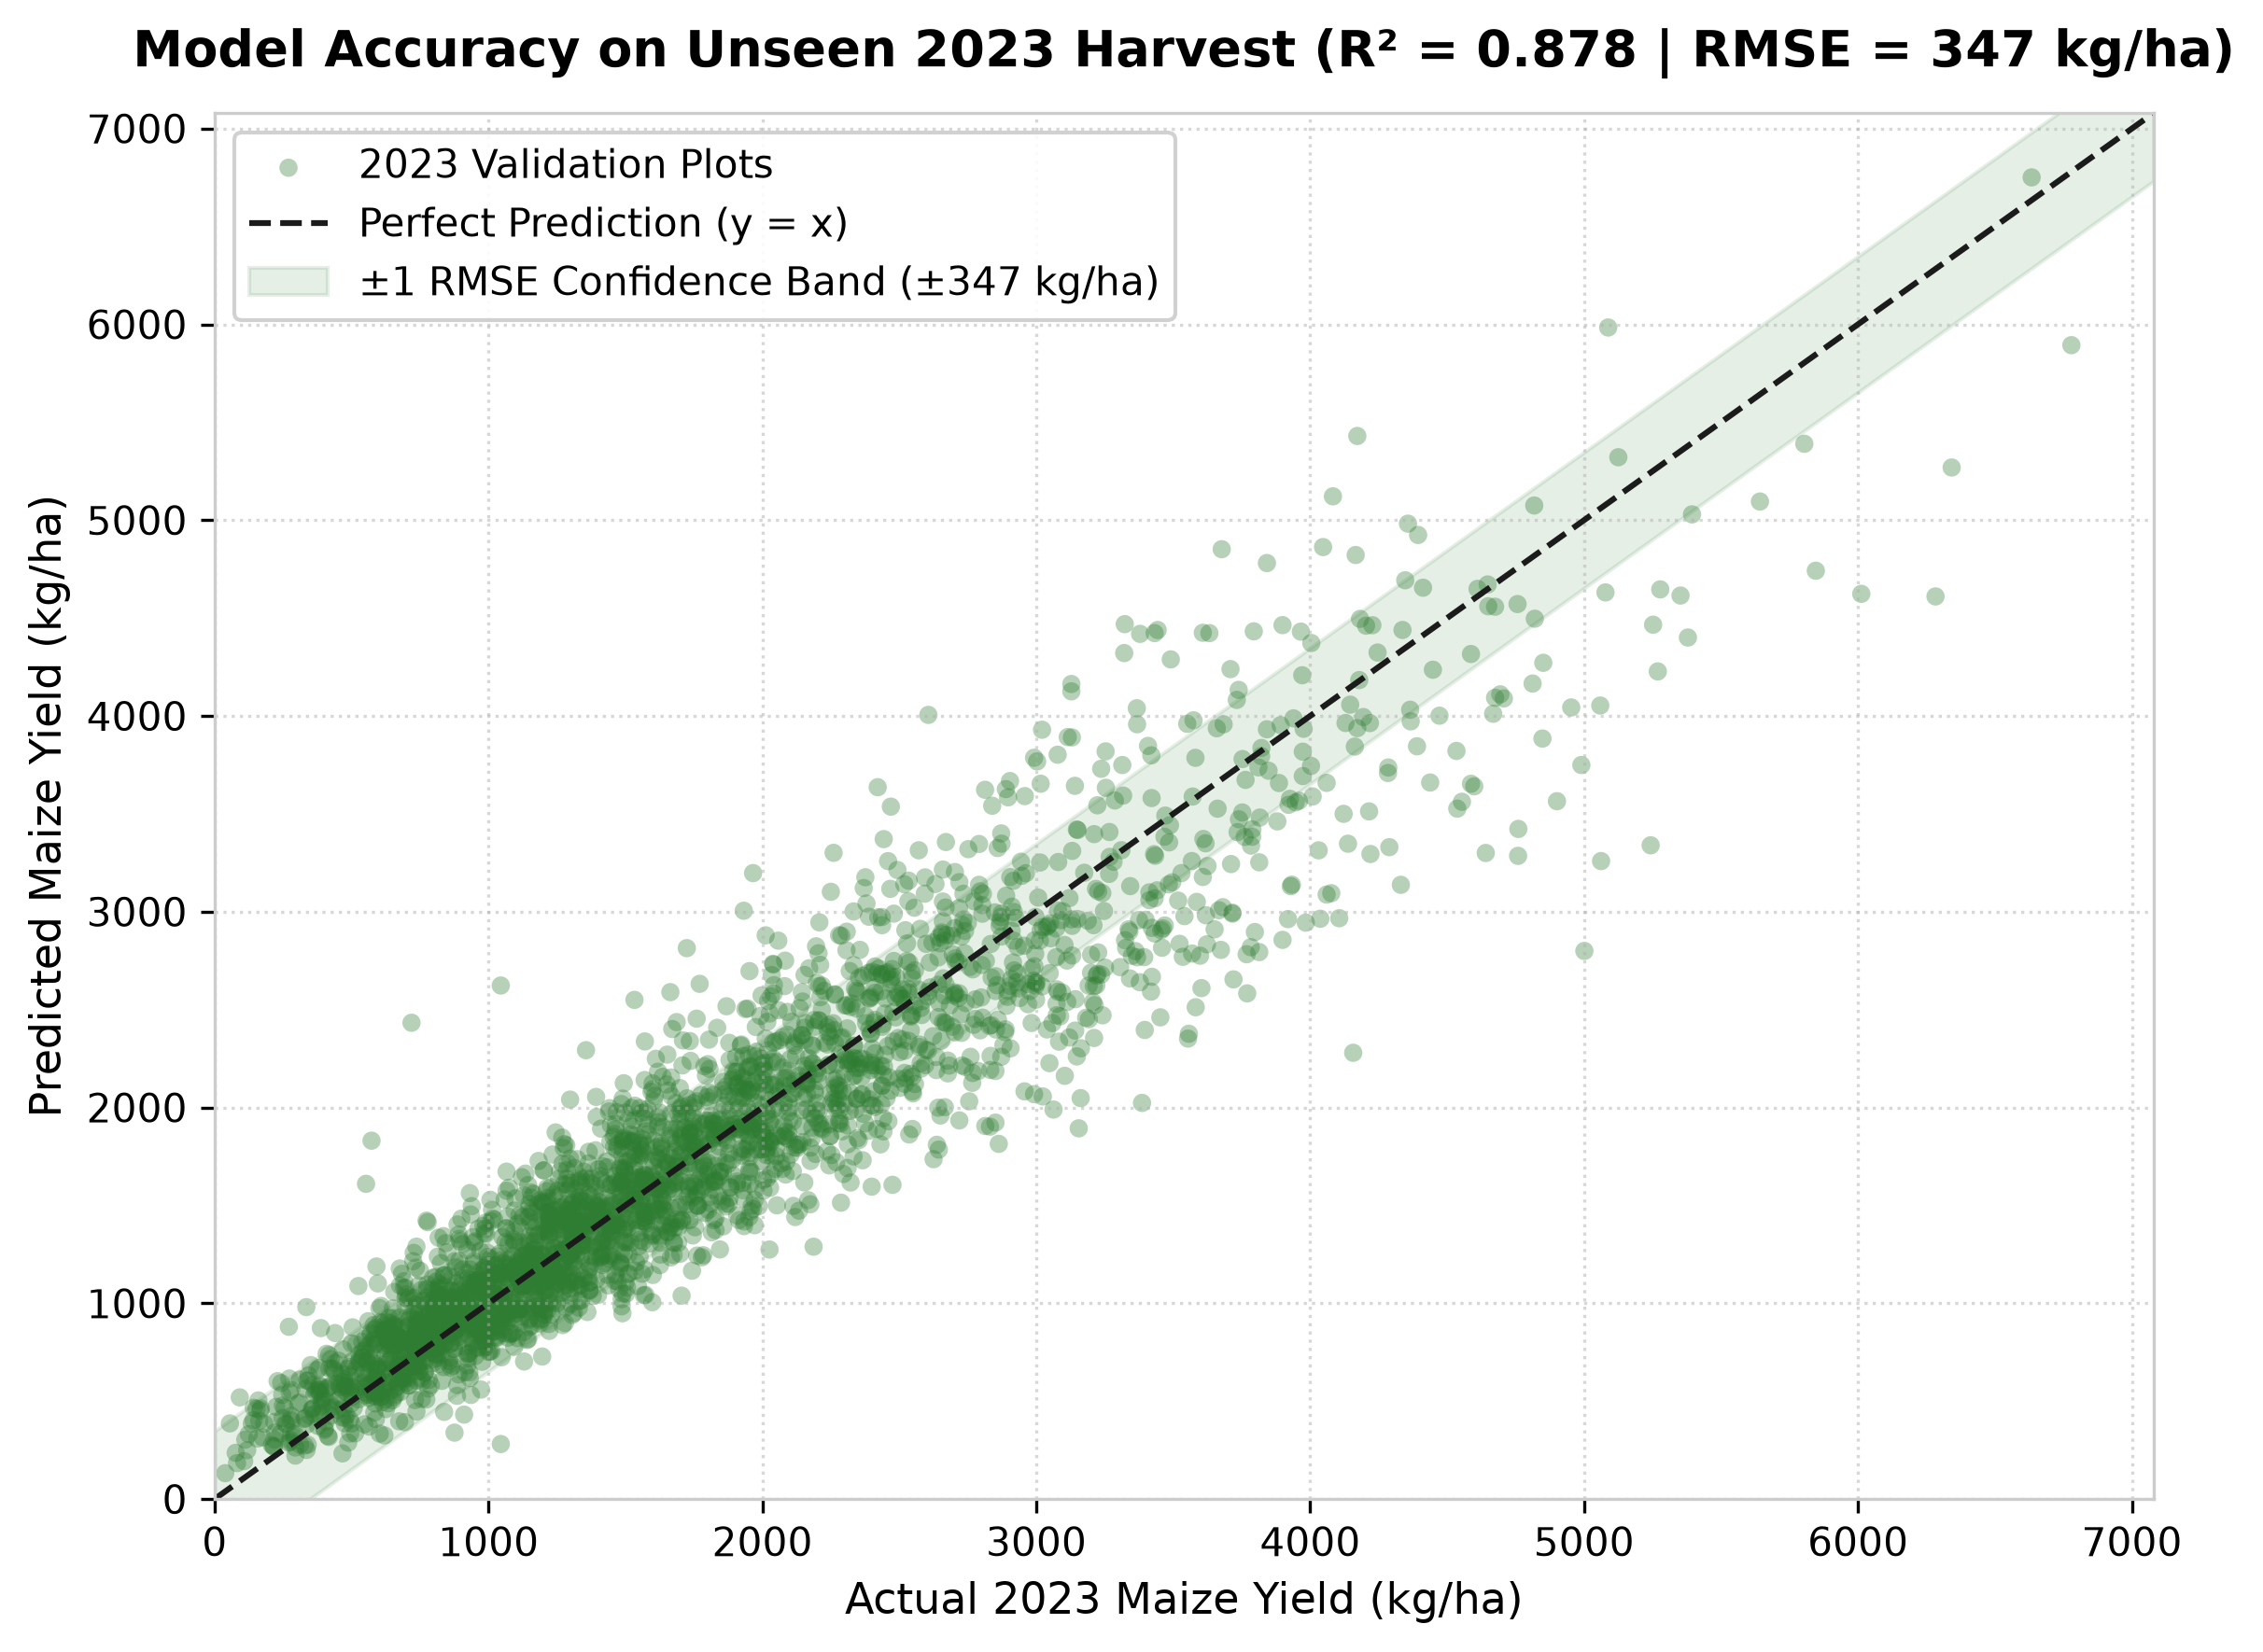

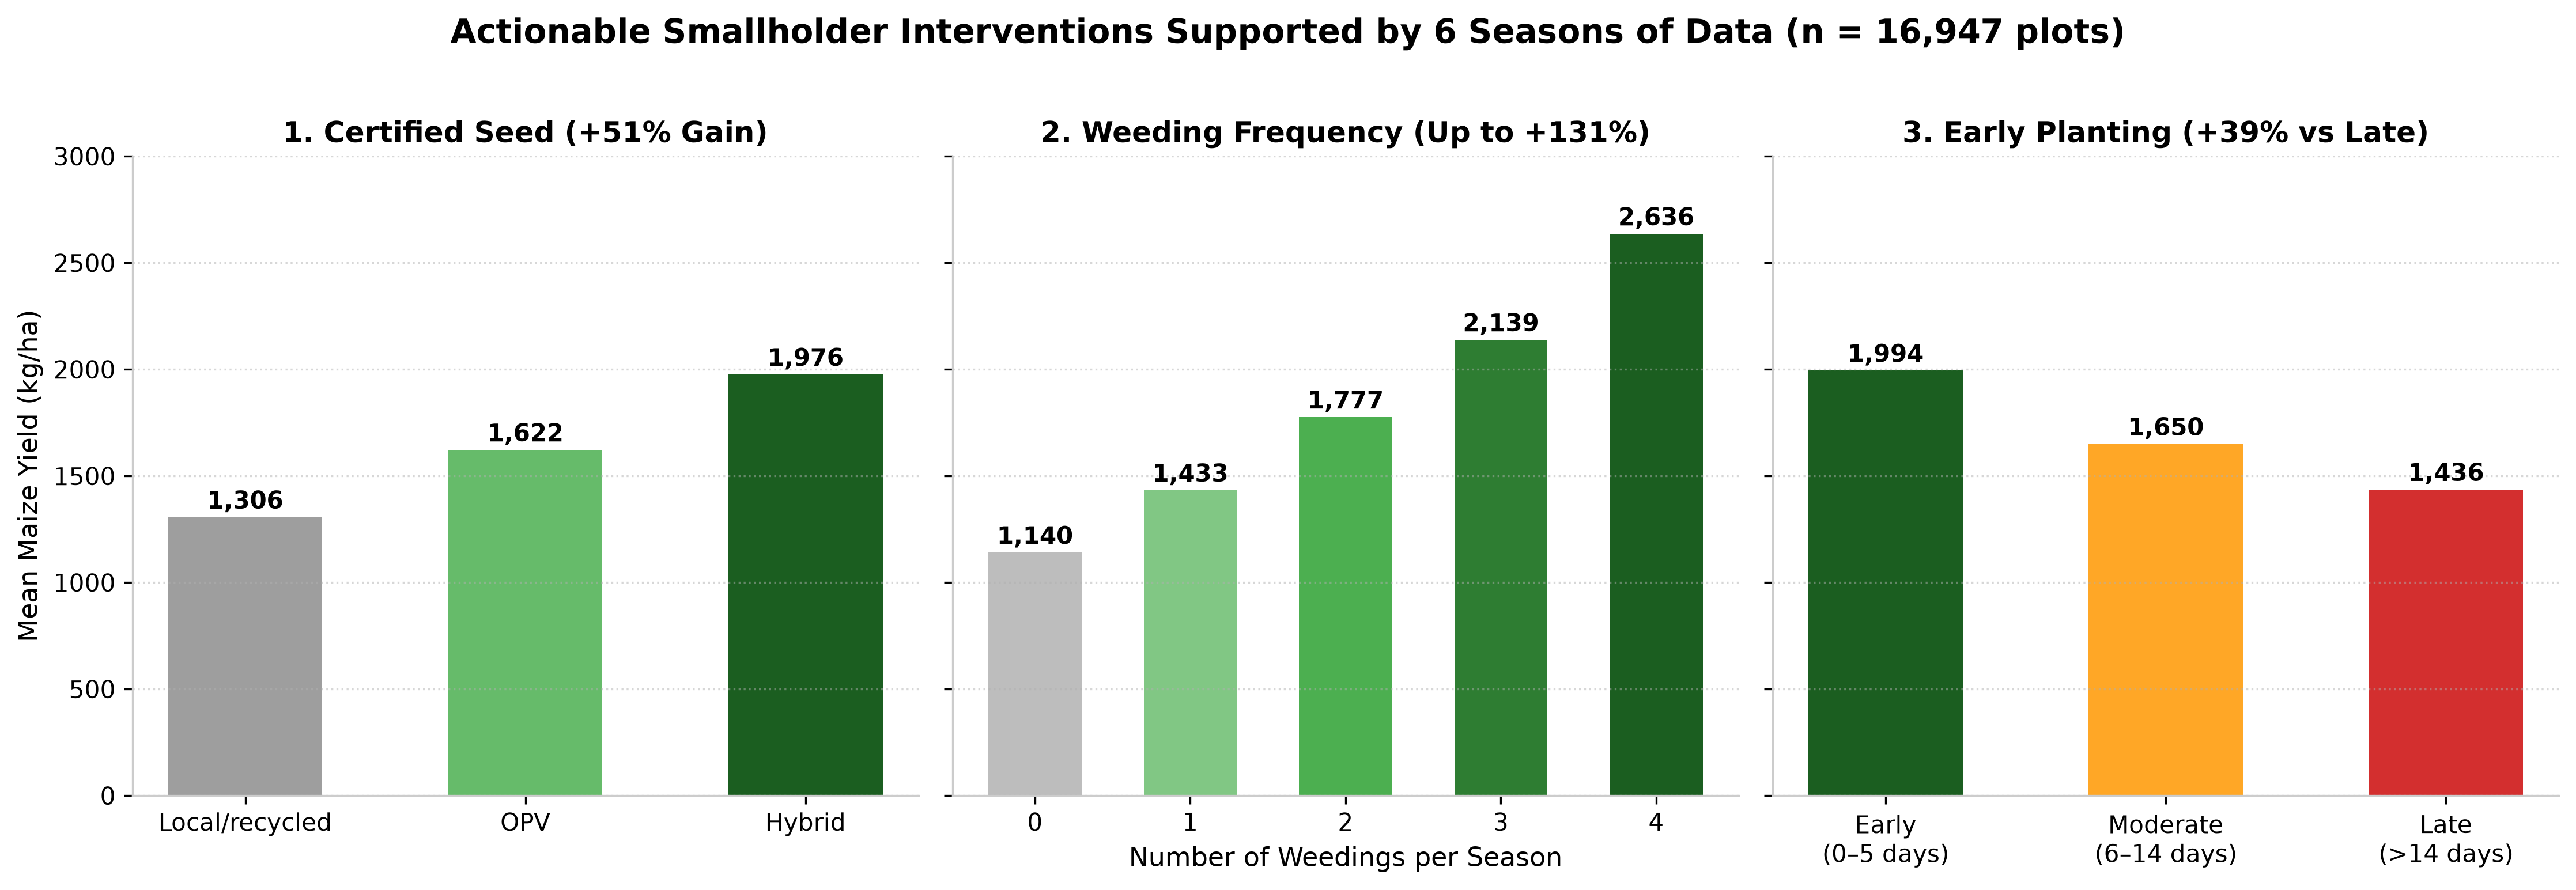

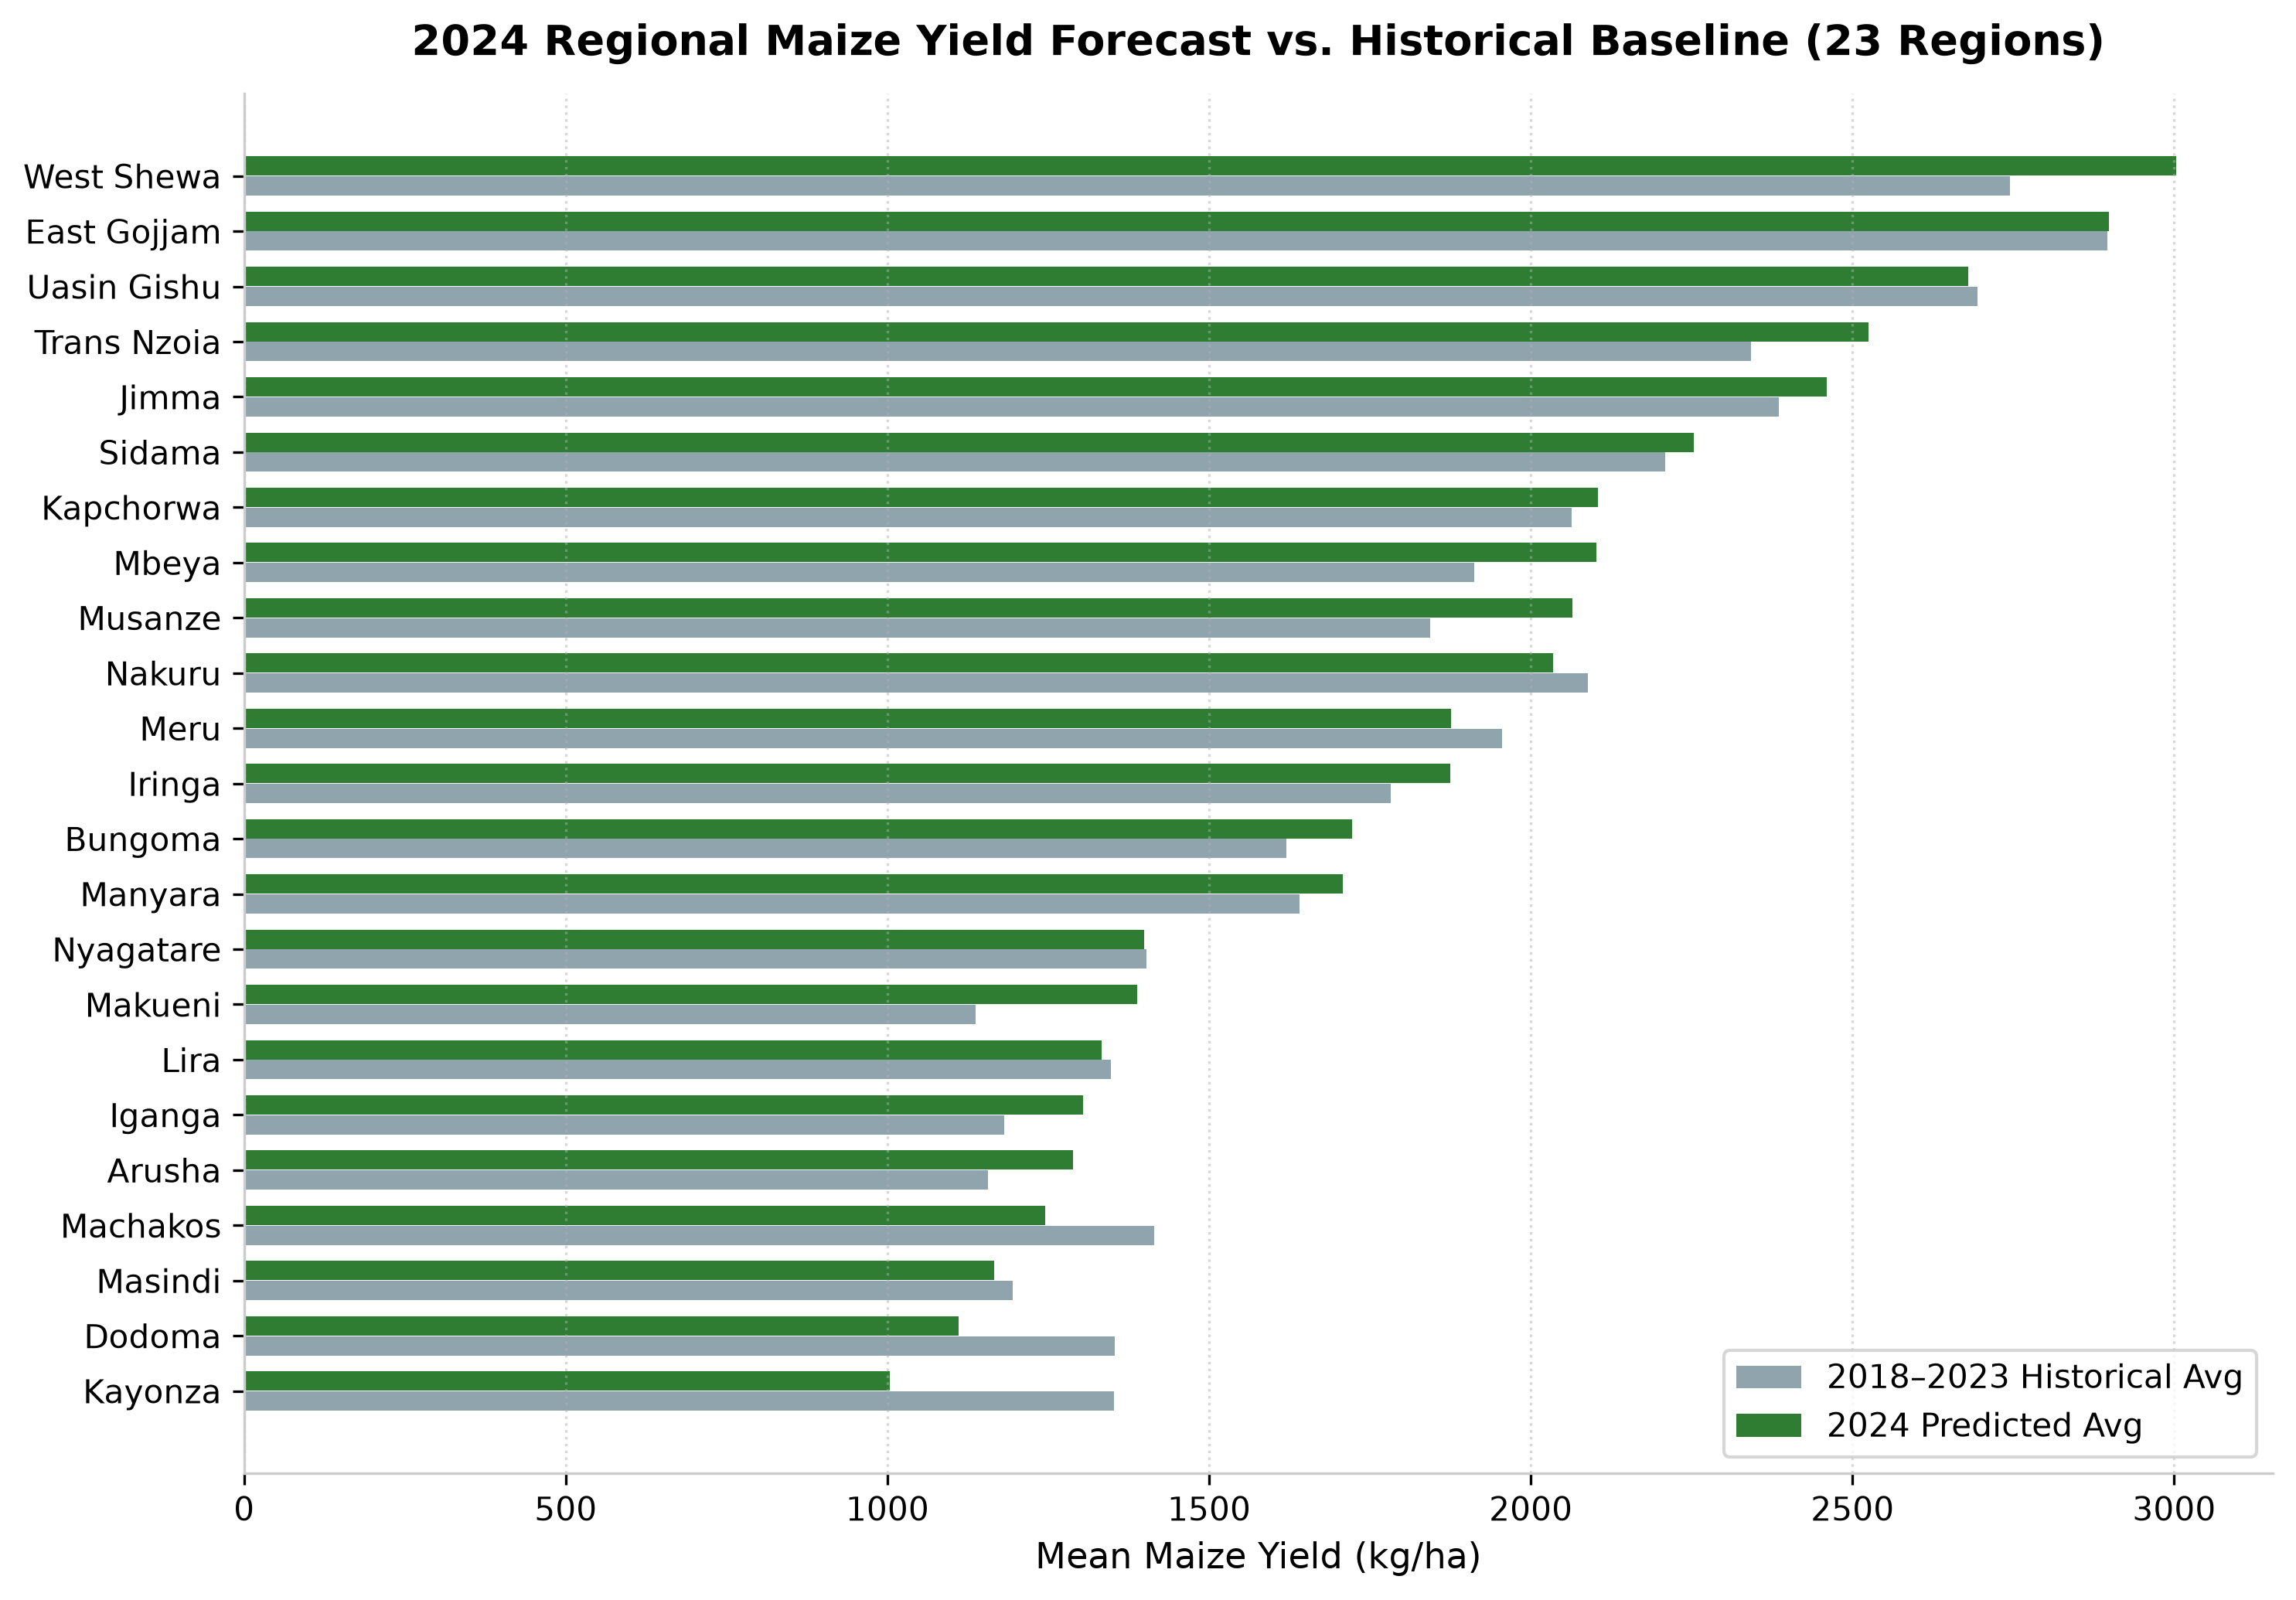

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingRegressor

# 1. Load & Clean
train = pd.read_csv('train.csv')
test = pd.read_csv('test.csv')

train_clean = train.drop_duplicates(subset=['record_id']).reset_index(drop=True)
test_clean = test.copy()

for df in [train_clean, test_clean]:
    df['seed_type'] = df['seed_type'].str.strip().str.capitalize().replace({'Opv': 'OPV'})
    df['intercrop'] = df['intercrop'].str.strip().str.capitalize()

soil_cols = ['soil_ph', 'soil_organic_carbon_pct', 'soil_nitrogen_pct', 'soil_p_ppm']
all_farms = pd.concat([train_clean[['farm_id', 'soil_type'] + soil_cols],
                       test_clean[['farm_id', 'soil_type'] + soil_cols]])
farm_soil_map = all_farms.groupby('farm_id')[soil_cols].median()
soil_type_map = train_clean.groupby('soil_type')[soil_cols].median()

for col in soil_cols:
    train_clean[col] = train_clean[col].fillna(train_clean['farm_id'].map(farm_soil_map[col])).fillna(train_clean['soil_type'].map(soil_type_map[col]))
    test_clean[col] = test_clean[col].fillna(test_clean['farm_id'].map(farm_soil_map[col])).fillna(test_clean['soil_type'].map(soil_type_map[col]))

num_missing_cols = ['ndvi_peak', 'manure_t_ha', 'education_years', 'seed_rate_kg_ha',
                    'hh_head_age', 'fertilizer_urea_kg_ha', 'longest_dry_spell_days']
for col in num_missing_cols:
    med = train_clean[col].median()
    train_clean[col] = train_clean[col].fillna(med)
    test_clean[col] = test_clean[col].fillna(med)

# 2. Engineer Features
raw_train_dedup = train.drop_duplicates(subset=['record_id']).reset_index(drop=True)
cat_cols = ['country', 'region', 'agro_ecological_zone', 'season',
            'hh_head_gender', 'soil_type', 'seed_type', 'intercrop', 'faw_incidence']

def prep_features(df, raw_df):
    d = df.copy()
    d['total_fertilizer_kg_ha'] = d['fertilizer_dap_kg_ha'] + d['fertilizer_urea_kg_ha']
    d['drought_stress'] = d['longest_dry_spell_days'] / (d['seasonal_rainfall_mm'] + 1)
    d['disease_count'] = d['mln_reported'] + d['striga_present']
    d['has_soil_test'] = raw_df['soil_ph'].notnull().astype(int)
    for col in cat_cols:
        d[col] = d[col].astype('category')
    return d

train_feat = prep_features(train_clean, raw_train_dedup)
test_feat = prep_features(test_clean, test)
features = [c for c in train_feat.columns if c not in ['record_id', 'farm_id', 'yield_kg_ha']]

# 3. 2023 Validation Predictions (for Chart 1)
val_mask = train_feat['year'] == 2023
past_data = train_feat[~val_mask]
farm_hist = past_data.groupby('farm_id')['yield_kg_ha'].mean()
region_hist = past_data.groupby('region', observed=False)['yield_kg_ha'].mean()
global_hist = past_data['yield_kg_ha'].mean()

farm_sum = past_data.groupby('farm_id')['yield_kg_ha'].transform('sum')
farm_cnt = past_data.groupby('farm_id')['yield_kg_ha'].transform('count')
loo_mean = ((farm_sum - past_data['yield_kg_ha']) / (farm_cnt - 1)).fillna(past_data['region'].map(region_hist)).fillna(global_hist)

X_tr = train_feat.loc[~val_mask, features].copy()
X_tr['farm_hist_yield'] = loo_mean.values
y_tr = train_feat.loc[~val_mask, 'yield_kg_ha']

X_val = train_feat.loc[val_mask, features].copy()
X_val['farm_hist_yield'] = train_feat.loc[val_mask, 'farm_id'].map(farm_hist).fillna(
    train_feat.loc[val_mask, 'region'].map(region_hist)).fillna(global_hist).values
y_val = train_feat.loc[val_mask, 'yield_kg_ha']

model_v2 = HistGradientBoostingRegressor(random_state=42).fit(X_tr, y_tr)
val_preds_v2 = model_v2.predict(X_val)

# 4. Full Model & 2024 Forecast (for Chart 3)
full_farm_hist = train_feat.groupby('farm_id')['yield_kg_ha'].mean()
full_region_hist = train_feat.groupby('region', observed=False)['yield_kg_ha'].mean()
full_sum = train_feat.groupby('farm_id')['yield_kg_ha'].transform('sum')
full_cnt = train_feat.groupby('farm_id')['yield_kg_ha'].transform('count')
full_loo = ((full_sum - train_feat['yield_kg_ha']) / (full_cnt - 1)).fillna(train_feat['region'].map(full_region_hist)).fillna(global_hist)

X_full = train_feat[features].copy()
X_full['farm_hist_yield'] = full_loo.values
X_test_final = test_feat[features].copy()
X_test_final['farm_hist_yield'] = test_feat['farm_id'].map(full_farm_hist).fillna(
    test_feat['region'].map(full_region_hist)).fillna(global_hist).values

final_model = HistGradientBoostingRegressor(random_state=42).fit(X_full, train_feat['yield_kg_ha'])
preds_2024 = np.clip(final_model.predict(X_test_final), 0, None)

# 5. Generate & Save the 3 Charts
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#CCCCCC'
plt.rcParams['axes.linewidth'] = 0.8

# CHART 1
fig, ax = plt.subplots(figsize=(8, 6), dpi=300)
ax.scatter(y_val, val_preds_v2, alpha=0.35, color='#2E7D32', edgecolors='none', s=22, label='2023 Validation Plots')
lims = [0, max(y_val.max(), val_preds_v2.max()) + 300]
ax.plot(lims, lims, '--', color='#1B1B1B', linewidth=1.5, label='Perfect Prediction (y = x)')
ax.fill_between(lims, [x - 347.34 for x in lims], [x + 347.34 for x in lims], color='#2E7D32', alpha=0.12, label='±1 RMSE Confidence Band (±347 kg/ha)')
ax.set_xlim(lims); ax.set_ylim(lims)
ax.set_title('Model Accuracy on Unseen 2023 Harvest (R² = 0.878 | RMSE = 347 kg/ha)', fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('Actual 2023 Maize Yield (kg/ha)', fontsize=11)
ax.set_ylabel('Predicted Maize Yield (kg/ha)', fontsize=11)
ax.legend(loc='upper left', frameon=True, facecolor='white', framealpha=0.9)
ax.grid(True, linestyle=':', alpha=0.5)
plt.tight_layout()
plt.savefig('chart1_model_trust.png', dpi=300)
plt.show()

# CHART 2
fig, axes = plt.subplots(1, 3, figsize=(15, 5), dpi=300, sharey=True)
seed_order = ['Local/recycled', 'OPV', 'Hybrid']
seed_means = train_clean.groupby('seed_type')['yield_kg_ha'].mean().reindex(seed_order)
bars1 = axes[0].bar(seed_order, seed_means, color=['#9E9E9E', '#66BB6A', '#1B5E20'], width=0.55)
axes[0].set_title('1. Certified Seed (+51% Gain)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Mean Maize Yield (kg/ha)', fontsize=11)
for bar in bars1:
    h = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2, h + 40, f'{h:,.0f}', ha='center', fontweight='bold', fontsize=10)

weed_means = train_clean.groupby('weeding_count')['yield_kg_ha'].mean()
bars2 = axes[1].bar(weed_means.index.astype(str), weed_means.values, color=['#BDBDBD', '#81C784', '#4CAF50', '#2E7D32', '#1B5E20'], width=0.6)
axes[1].set_title('2. Weeding Frequency (Up to +131%)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Number of Weedings per Season', fontsize=11)
for bar in bars2:
    h = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width()/2, h + 40, f'{h:,.0f}', ha='center', fontweight='bold', fontsize=10)

delay_bins = pd.cut(train_clean['planting_delay_days'], bins=[-1, 5, 14, 100], labels=['Early\n(0–5 days)', 'Moderate\n(6–14 days)', 'Late\n(>14 days)'])
delay_means = train_clean.groupby(delay_bins, observed=False)['yield_kg_ha'].mean()
bars3 = axes[2].bar(delay_means.index.astype(str), delay_means.values, color=['#1B5E20', '#FFA726', '#D32F2F'], width=0.55)
axes[2].set_title('3. Early Planting (+39% vs Late)', fontsize=12, fontweight='bold')
for bar in bars3:
    h = bar.get_height()
    axes[2].text(bar.get_x() + bar.get_width()/2, h + 40, f'{h:,.0f}', ha='center', fontweight='bold', fontsize=10)

for ax in axes:
    ax.set_ylim(0, 3000)
    ax.grid(axis='y', linestyle=':', alpha=0.5)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

fig.suptitle('Actionable Smallholder Interventions Supported by 6 Seasons of Data (n = 16,947 plots)', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('chart2_farmer_levers.png', dpi=300, bbox_inches='tight')
plt.show()

# CHART 3
test_with_preds = test_feat.copy()
test_with_preds['predicted_2024'] = preds_2024
reg_comp = pd.DataFrame({
    'Historical (2018-2023)': train_clean.groupby('region')['yield_kg_ha'].mean(),
    'Forecast (2024)': test_with_preds.groupby('region')['predicted_2024'].mean()
}).sort_values('Forecast (2024)')

fig, ax = plt.subplots(figsize=(10, 7), dpi=300)
y_pos = np.arange(len(reg_comp))
ax.barh(y_pos - 0.18, reg_comp['Historical (2018-2023)'], height=0.35, color='#90A4AE', label='2018–2023 Historical Avg')
ax.barh(y_pos + 0.18, reg_comp['Forecast (2024)'], height=0.35, color='#2E7D32', label='2024 Predicted Avg')
ax.set_yticks(y_pos)
ax.set_yticklabels(reg_comp.index, fontsize=10)
ax.set_xlabel('Mean Maize Yield (kg/ha)', fontsize=11)
ax.set_title('2024 Regional Maize Yield Forecast vs. Historical Baseline (23 Regions)', fontsize=13, fontweight='bold', pad=12)
ax.legend(loc='lower right', frameon=True)
ax.grid(axis='x', linestyle=':', alpha=0.5)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig('chart3_regional_forecast_2024.png', dpi=300)
plt.show()

In [7]:
import joblib

# Compute median/mode defaults per region so a user only has to pick a Region
# and tweak key levers without manually typing 42 columns!
region_defaults = {}
for reg, group in train_clean.groupby('region'):
    region_defaults[reg] = {
        'country': group['country'].mode()[0],
        'agro_ecological_zone': group['agro_ecological_zone'].mode()[0],
        'latitude': float(group['latitude'].median()),
        'longitude': float(group['longitude'].median()),
        'altitude_m': float(group['altitude_m'].median()),
        'season': group['season'].mode()[0],
        'farm_size_ha': float(group['farm_size_ha'].median()),
        'plot_size_ha': float(group['plot_size_ha'].median()),
        'hh_head_gender': group['hh_head_gender'].mode()[0],
        'hh_head_age': float(group['hh_head_age'].median()),
        'hh_size': float(group['hh_size'].median()),
        'education_years': float(group['education_years'].median()),
        'coop_member': int(group['coop_member'].mode()[0]),
        'extension_visits': float(group['extension_visits'].median()),
        'access_to_credit': int(group['access_to_credit'].mode()[0]),
        'distance_to_market_km': float(group['distance_to_market_km'].median()),
        'soil_type': group['soil_type'].mode()[0],
        'soil_ph': float(group['soil_ph'].median()),
        'soil_organic_carbon_pct': float(group['soil_organic_carbon_pct'].median()),
        'soil_nitrogen_pct': float(group['soil_nitrogen_pct'].median()),
        'soil_p_ppm': float(group['soil_p_ppm'].median()),
        'slope_pct': float(group['slope_pct'].median()),
        'seed_rate_kg_ha': float(group['seed_rate_kg_ha'].median()),
        'manure_t_ha': float(group['manure_t_ha'].median()),
        'intercrop': group['intercrop'].mode()[0],
        'pesticide_used': int(group['pesticide_used'].mode()[0]),
        'irrigation': int(group['irrigation'].mode()[0]),
        'seasonal_rainfall_mm': float(group['seasonal_rainfall_mm'].median()),
        'rainfall_onset_doy': float(group['rainfall_onset_doy'].median()),
        'longest_dry_spell_days': float(group['longest_dry_spell_days'].median()),
        'mean_tmax_c': float(group['mean_tmax_c'].median()),
        'ndvi_peak': float(group['ndvi_peak'].median()),
        'mln_reported': 0,
        'striga_present': 0,
        'farm_hist_yield': float(group['yield_kg_ha'].mean())
    }

# Save everything into a single artifact
artifact = {
    'model': final_model,
    'features': features + ['farm_hist_yield'],
    'cat_cols': cat_cols,
    'region_defaults': region_defaults,
    'test_forecasts': test_with_preds[['record_id', 'country', 'region', 'agro_ecological_zone', 
                                       'seed_type', 'total_fertilizer_kg_ha', 'faw_incidence', 'predicted_2024']]
}

joblib.dump(artifact, 'shamba_model.pkl')
print("Saved shamba_model.pkl successfully!")

Saved shamba_model.pkl successfully!
